In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from load_results import load, format
df = load()
df = format(df)
df = df.drop(columns=["selection_strategy_name_a", "selection_strategy_name_b"])

In [2]:
df.score_name.unique()

array(['sign_agreement', 'rbo', 'spearman_rho', 'ndcg', 'unbiased_cka',
       'cka'], dtype=object)

In [3]:
df.columns

Index(['Experiment', 'Rep_A', 'Rep_B', 'score_name', 'score', 'k', 'normalize',
       'model', 'train_dataset', 'train_dataset_split', 'test_dataset',
       'test_dataset_split', 'base_model', 'test_type'],
      dtype='object')

In [4]:
scores_to_plot = [
    "cka", 
    "spearman_rho"]

score_name cka -1 False


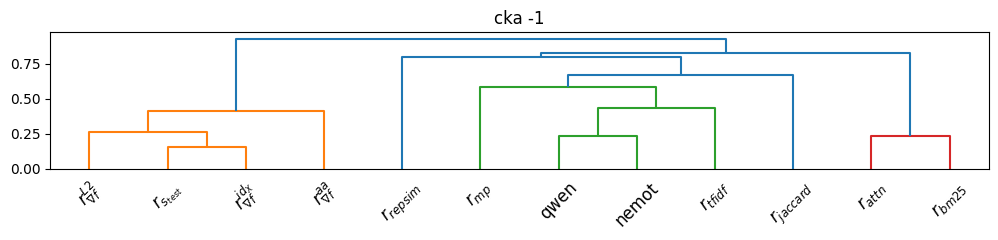

score_name cka -1 True


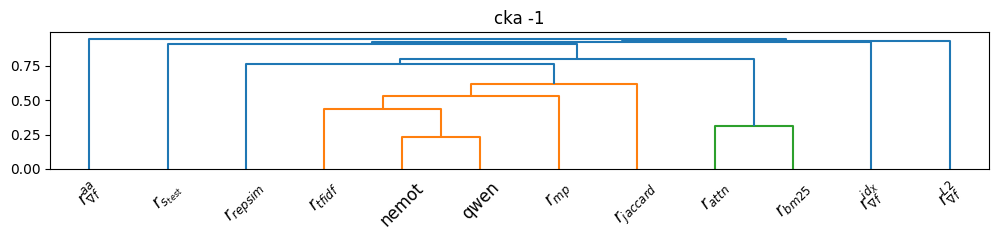

score_name spearman_rho -1 False


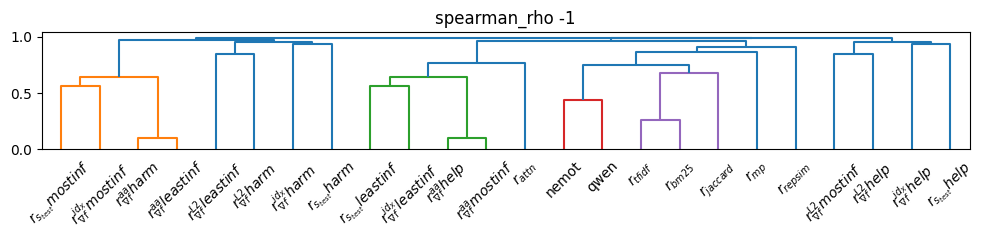

In [5]:
def build_dist_matrix_condensed(df_):
    df_sym = pd.concat([
        df_,
        df_.rename(columns={"Rep_A": "Rep_B", "Rep_B": "Rep_A"})
    ], ignore_index=True)

    # 2. get reps from THIS group only
    reps = pd.unique(df_sym[["Rep_A", "Rep_B"]].values.ravel())

    # 3. create diagonal for THIS group
    df_diag = pd.DataFrame({
        "Rep_A": reps,
        "Rep_B": reps,
        "score": 1.0
    })
    
    # 4. add diagonal
    df_full = pd.concat([df_sym, df_diag], ignore_index=True)
    
    cka_mat = (
        df_full
        .pivot_table(
            index="Rep_A",
            columns="Rep_B",
            values="score",
            aggfunc="mean"
        )
    )
    cka_mat = cka_mat.reindex(index=reps, columns=reps)
    cka_mat =  np.clip(cka_mat, 0.0, 1.0)
    dist = 1 - cka_mat
    return  squareform(dist, checks=False), cka_mat.index, cka_mat




for (score_name, k, normalize), df_ in df.groupby(["score_name", "k", "normalize"]):#df["score_name"].unique():
    if score_name not in scores_to_plot:
        continue
    print("score_name",score_name, k, normalize)
    
   
    
    dist_mat, labels,_ = build_dist_matrix_condensed(df_)
    Z = linkage(dist_mat, method="average",optimal_ordering=True)


    plt.figure(figsize=(10,2.5))
    dendrogram(Z, labels=labels, leaf_rotation=45)
    plt.title(f"{score_name} {k}")
    plt.tight_layout()
    plt.show()



In [6]:
# correlation between hierarchical geometries of two experiments
# Do Experiment A and Experiment B produce the same structure of relationships between representations?
# average structural stability of representation geometry across experiments
# how invariant the hierarchical organization of representation similarities is across experimental conditions

In [7]:
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, cophenet
from scipy.stats import spearmanr
from itertools import combinations


def build_cophenetic(condensed):
    Z = linkage(condensed, method="average", optimal_ordering=True)
    _, coph = cophenet(Z, condensed)
    return coph


def corr_coph(df, group_by):
    
    results = []

    for (score_name, k, normalize), g in df.groupby(["score_name", "k", "normalize"]):

        structures = {}

        for name, sub in g.groupby(group_by):
            
            try:
                condensed, labels, _ = build_dist_matrix_condensed(sub)
                structures[name] = (labels, build_cophenetic(condensed))
            except Exception as e:
                print("skipping", score_name, k, name, "|", e)
      

        for a, b in combinations(structures.keys(), 2):

            lab1, coph1 = structures[a]
            lab2, coph2 = structures[b]

            common = sorted(set(lab1) & set(lab2))
            if len(common) < 2:
                continue

            i1 = {x: i for i, x in enumerate(lab1)}
            i2 = {x: i for i, x in enumerate(lab2)}

            x = coph1[[i1[c] for c in common]]
            y = coph2[[i2[c] for c in common]]

            corr = spearmanr(x, y)[0]

            results.append({
                # "group_by": group_by,
                "Group": a[0],
                "A": a[1],
                "B": b[1],
                "score_name": score_name,
                "k": k,
                "normalize": normalize,
                "measure": "spearmanr",
                "cophenetic_corr": corr
            })

    return pd.DataFrame(results)



$\bar{\rho}_{d}(b_i,b_j)=\mathbb{E}_{b_i < b_j}\big[\rho_{\mathrm{coph}}(b_i, b_j \mid d)\big],$

In [19]:
# i
corr_coph(df[(~df["normalize"]) & (df["score_name"].isin(scores_to_plot))], group_by=["Experiment", "base_model",])\
    .groupby(["score_name", "Group", "k", "normalize", "measure"]).mean(numeric_only=True)\
        .style.background_gradient(
            cmap="viridis",
            subset=["cophenetic_corr"],
            axis=0
        )

$\bar{\rho}_{b}(d_i, d_j)=\mathbb{E}_{d_i < d_j}\big[\rho_{\mathrm{coph}}(d_i, d_j \mid b)\big].$

In [20]:
corr_coph(df[(~df["normalize"]) & (df["score_name"].isin(scores_to_plot))], group_by=["base_model","Experiment", ])\
    .groupby(["score_name", "Group", "k", "normalize", "measure"]).mean(numeric_only=True)\
        .style.background_gradient(
            cmap="viridis",
            subset=["cophenetic_corr"],
            axis=0
        )